# Figure 5, Panel F

# Setup

In [1]:
#load packages
library(tidyverse)
library(patchwork)
library(here)
here::i_am("figures/Figure5/PanelF/PanelF.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank()))
sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/Figure5/PanelF

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      patchwork_1.3.0 lubridate_1.9.4 forcats_1.0.0  
 [5] stringr_1.5.1   dplyr_1.1.4     purrr_1.0.2     readr_2.1.5    
 [9] tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    ba

# Load data

In [2]:
#PCHiC contacts w/ ATAC-seq overlaps, annotated with gene expression changes with stimulus and/or BAFinh, analagously for accessibility changes at cREs
contacts_hg38_atac_rna <- read.delim(
  here(
    "figures", "SuppFig5", "PanelH",
    "GM12878_PCHi-C_ATAC_RNA.tsv"
  ),
  sep = "\t"
)

# Generate plots

`summarise()` has grouped output by 'ind'. You can override using the `.groups`
argument.
`summarise()` has grouped output by 'ind'. You can override using the `.groups`
argument.
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
Saving 3.5 x 7 in image
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


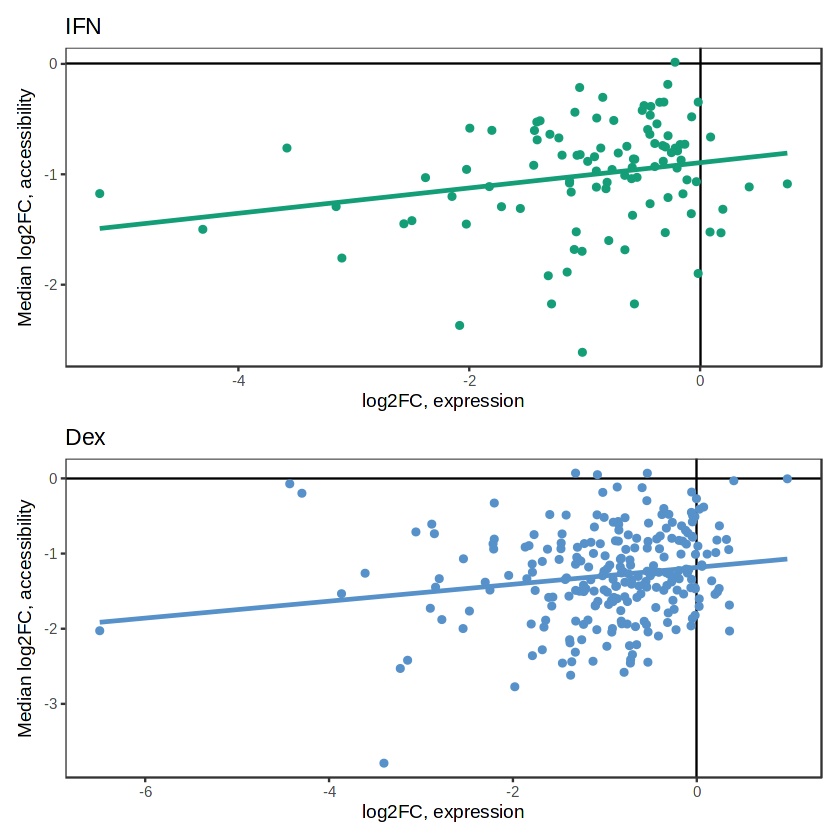

In [3]:
dex_col <- "#5791c9"
ifn_col <- "#149e77"

p1 <- contacts_hg38_atac_rna %>% 
    mutate(ind=case_when(ifn_ind ~ "ifn", dex_ind ~ "dex", TRUE ~ "none")) %>%
    filter(ind=="ifn") %>% 
    group_by(ind, gene_symbol) %>%
    summarize(rna_fc = mean(brm_ifn_6h_log2fc), 
              max_atac=min(fc_brm_ifn_atac), 
              median_atac=median(fc_brm_ifn_atac),
              mean_atac=mean(fc_brm_ifn_atac),
              weighted_avg=sum(loe*fc_brm_ifn_atac)/sum(loe)
) %>%
    ggplot(aes(x=rna_fc, y=median_atac)) + geom_hline(yintercept=0) + geom_vline(xintercept=0) + geom_point(color=ifn_col) + geom_smooth(method=lm, se=F, color=ifn_col) + ggtitle("IFN") +
    ylab("Median log2FC, accessibility") + xlab("log2FC, expression")

p2 <- contacts_hg38_atac_rna %>% 
    mutate(ind=case_when(ifn_ind ~ "ifn", dex_ind ~ "dex", TRUE ~ "none")) %>%
    filter(ind=="dex") %>% 
    group_by(ind, gene_symbol) %>%
    summarize(rna_fc = mean(brm_dex_6h_log2fc), 
              max_atac=min(fc_brm_dex_atac), 
              median_atac=median(fc_brm_dex_atac),
              mean_atac=mean(fc_brm_dex_atac),
              weighted_avg=sum(loe*fc_brm_dex_atac)/sum(loe)
) %>%
    ggplot(aes(x=rna_fc, y=median_atac)) + geom_hline(yintercept=0) + geom_vline(xintercept=0) + geom_point(color=dex_col) + geom_smooth(method=lm, se=F, color=dex_col) + ggtitle("Dex") +
    ylab("Median log2FC, accessibility") + xlab("log2FC, expression")

p1/p2
ggsave("PanelF.pdf",width=3.5)

# Statistics

In [6]:
ifn <- contacts_hg38_atac_rna %>% filter(ifn_ind ==T) %>%
    group_by(gene_symbol) %>%
    summarize(rna_fc = mean(brm_ifn_6h_log2fc), 
              median_atac=median(fc_brm_ifn_atac))

cor.test(ifn$rna_fc, ifn$median_atac)

dex <- contacts_hg38_atac_rna %>% filter(dex_ind ==T) %>%
    group_by(gene_symbol) %>%
    summarize(rna_fc = mean(brm_dex_6h_log2fc), 
              median_atac=median(fc_brm_dex_atac))

cor.test(dex$rna_fc, dex$median_atac)


	Pearson's product-moment correlation

data:  ifn$rna_fc and ifn$median_atac
t = 2.2634, df = 100, p-value = 0.02577
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.02746192 0.39813984
sample estimates:
      cor 
0.2207578 



	Pearson's product-moment correlation

data:  dex$rna_fc and dex$median_atac
t = 2.9524, df = 256, p-value = 0.003446
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.06068114 0.29700460
sample estimates:
      cor 
0.1814615 


In [30]:
#Counts of Dex- and IFN-inducible genes included in PCHi-C dataset
(contacts_hg38_atac_rna %>% filter(dex_ind==T))$gene_symbol %>% unique() %>% length()
(contacts_hg38_atac_rna %>% filter(ifn_ind==T))$gene_symbol %>% unique() %>% length()

#Counts of Dex- and IFN-inducible genes with significantly reduced induction following BAFinh 
(contacts_hg38_atac_rna %>% filter(dex_ind_brm_rep == T))$gene_symbol %>% unique() %>% length()
(contacts_hg38_atac_rna %>% filter(ifn_ind_brm_rep == T))$gene_symbol %>% unique() %>% length()

#Counts of Dex- and IFN-inducible genes with significantly reduced induction following BAFinh  and are linked to cREs with significantly BAF-dep induction 
(contacts_hg38_atac_rna %>% filter(dex_ind_brm_rep == T & stim_repr_dex_atac==T))$gene_symbol %>% unique() %>% length()
(contacts_hg38_atac_rna %>% filter(ifn_ind_brm_rep == T & stim_repr_ifn_atac==T))$gene_symbol %>% unique() %>% length()


[1] 258

[1] 102

[1] 143

[1] 59

[1] 141

[1] 57